In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "dataset_bambu_multi_printer.csv",
    sep=",",
    engine="python",
    on_bad_lines="skip"
)

sns.set_theme(style="whitegrid")

# Conversión de timestamp
df['timestamp'] = pd.to_datetime(df['timestamp'])

print("=== 1. RESUMEN GENERAL ===")
print(f"Filas totales: {len(df):,}")
print(f"Rango de fechas: {df['timestamp'].min()} a {df['timestamp'].max()}")
print(f"Duplicados: {df.duplicated().sum()}")
print("\n=== 2. VALORES NULOS ===")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\n=== 3. REPARTO POR IMPRESERA Y TRAY ===")
print("Impresoras:\n", df['printer_name'].value_counts(normalize=True)*100)
print("\nBandejas:\n", df['tray_type'].value_counts(normalize=True)*100)
print("\nEstados GCode:\n", df['gcode_state'].value_counts(dropna=False, normalize=True)*100)

print("\n=== 4. ESTADÍSTICAS NUMÉRICAS ===")
print(df[['nozzle_temp', 'bed_temp', 'total_layer_num', 'mc_percent']].describe().round(1))

print("\n=== 5. CRUCE IMPRESORA VS ESTADO (%) ===")
print(pd.crosstab(df['printer_name'], df['gcode_state'], normalize='index').round(3)*100)

Nulos por columna:
 timestamp            0
printer_name         0
serial_number        0
gcode_state        473
mc_print_stage     473
tray_type            0
mc_percent           0
layer_num            0
total_layer_num      0
nozzle_temp          0
bed_temp             0
dtype: int64


In [25]:
# 1. Duplicados exactos
print("Duplicados:", df.duplicated().sum())

# 2. Valores nulos por columna
print("Valores nulos:\n", df.isnull().sum())

# 3. Mínimos y máximos de temperatura (para ver si hay 0°C o valores anómalos)
print(df[['nozzle_temp', 'bed_temp']].describe())

Duplicados: 1
Valores nulos:
 timestamp            0
printer_name         0
serial_number        0
gcode_state        473
mc_print_stage     473
tray_type            0
mc_percent           0
layer_num            0
total_layer_num      0
nozzle_temp          0
bed_temp             0
dtype: int64
        nozzle_temp      bed_temp
count  54584.000000  54584.000000
mean      60.822732     33.259197
std       70.487645     12.921619
min        0.000000      0.000000
25%       24.000000     23.000000
50%       27.000000     26.000000
75%       36.000000     44.000000
max      242.000000     56.000000


In [26]:
# 1. Reparto de carga por impresora
print("Registros por impresora:\n", df['printer_name'].value_counts())

# 2. Tipos de superficie/bandeja utilizadas
print("\nTipos de bandeja:\n", df['tray_type'].value_counts())

# 3. Complejidad de las piezas (número de capas)
print("\nResumen de capas totales:\n", df['total_layer_num'].describe().round(1))

Registros por impresora:
 printer_name
Bambu_H2D_1    28598
Bambu_H2D_2    25986
Name: count, dtype: int64

Tipos de bandeja:
 tray_type
Desconocido    38542
PLA            16042
Name: count, dtype: int64

Resumen de capas totales:
 count    54584.0
mean        51.8
std        115.8
min          0.0
25%         10.0
50%         10.0
75%         10.0
max        372.0
Name: total_layer_num, dtype: float64


In [27]:
# Promedio, mínimo y máximo de temperatura por tipo de bandeja
perfil_termico = df.groupby('tray_type')[['nozzle_temp', 'bed_temp']].agg(['mean', 'min', 'max'])
print(perfil_termico)

# Detectar impresoras funcionando con temperaturas inusualmente altas o bajas
anomalias_temp = df[(df['nozzle_temp'] > 260) | (df['nozzle_temp'] < 180)]

            nozzle_temp               bed_temp           
                   mean  min    max       mean  min   max
tray_type                                                
Desconocido   39.566473  0.0  223.0  28.100747  0.0  55.0
PLA          111.892345  0.0  242.0  45.652724  0.0  56.0


C:\Users\udaet\AppData\Local\Temp\ipykernel_21552\323326550.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='gcode_state', palette='viridis')


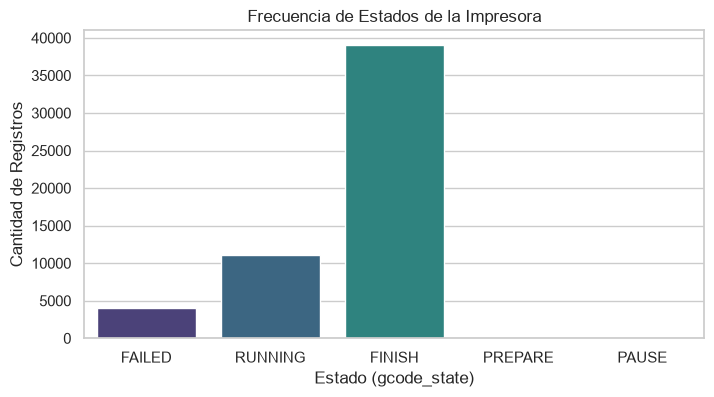

In [28]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='gcode_state', palette='viridis')
plt.title('Frecuencia de Estados de la Impresora')
plt.xlabel('Estado (gcode_state)')
plt.ylabel('Cantidad de Registros')
plt.show()

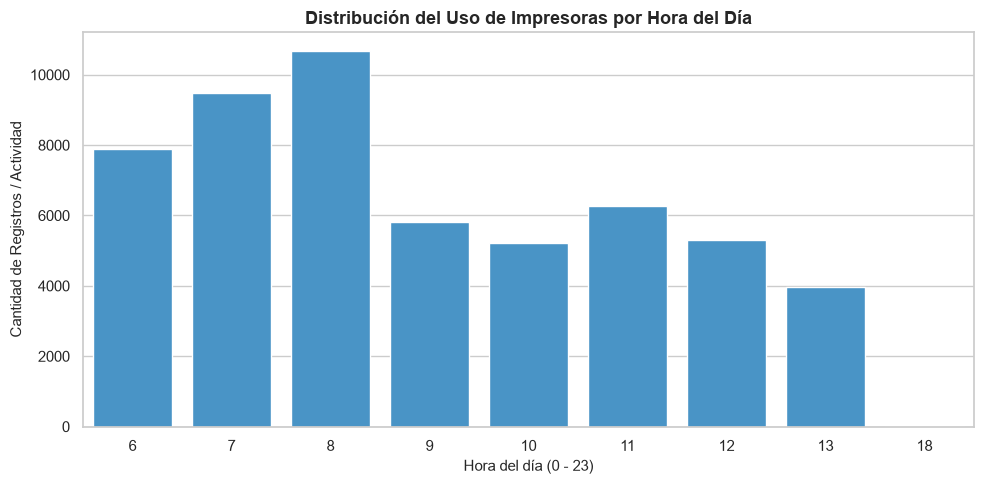

In [30]:
df['hora'] = df['timestamp'].dt.hour

# Configuración del estilo
plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")

# Gráfico de barras por hora del día
sns.countplot(data=df, x='hora', color='#3498db')

plt.title('Distribución del Uso de Impresoras por Hora del Día', fontsize=13, fontweight='bold')
plt.xlabel('Hora del día (0 - 23)', fontsize=11)
plt.ylabel('Cantidad de Registros / Actividad', fontsize=11)

plt.tight_layout()
plt.show()

In [32]:
# 1. Relación entre Impresora y Estado de Ejecución
print("--- Estado por Impresora ---")
print(pd.crosstab(df['printer_name'], df['gcode_state'], dropna=False))

# 2. Temperatura media de boquilla por Estado de GCode
print("\n--- Temperatura media por Estado ---")
print(df.groupby('gcode_state')['nozzle_temp'].mean().round(1))

--- Estado por Impresora ---
gcode_state   FAILED  FINISH  PAUSE  PREPARE  RUNNING  NaN
printer_name                                              
Bambu_H2D_1     3968   14363      5        3     9900  359
Bambu_H2D_2       27   24696      0        2     1147  114

--- Temperatura media por Estado ---
gcode_state
FAILED      36.2
FINISH      30.5
PAUSE       42.0
PREPARE     28.2
RUNNING    179.6
Name: nozzle_temp, dtype: float64


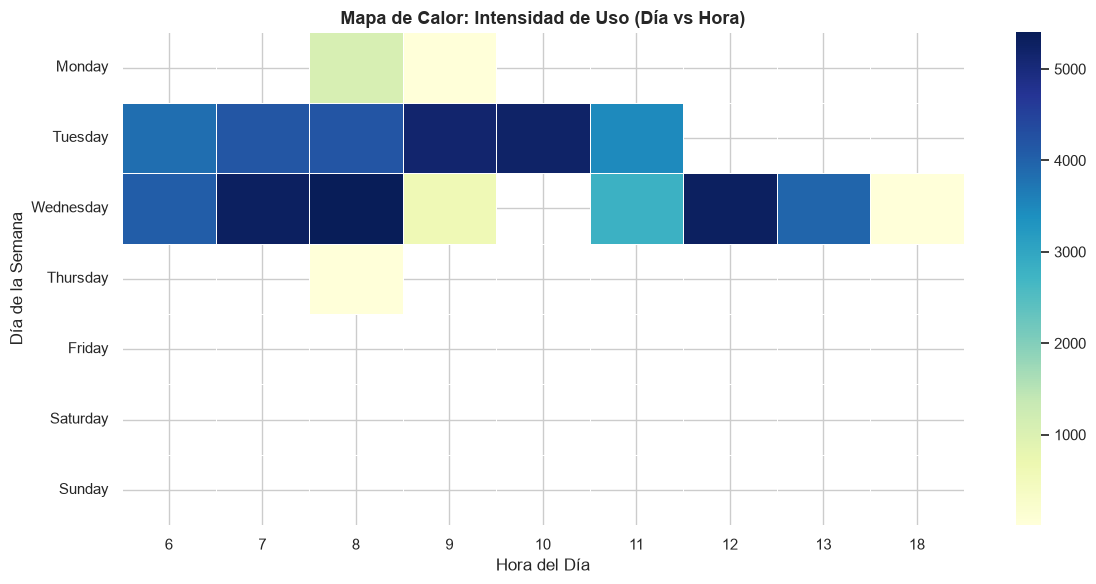

In [33]:
# Preparar datos de día de la semana u hora
df['dia_semana'] = df['timestamp'].dt.day_name()
dias_orden = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Crear tabla pivote
matriz_actividad = df.pivot_table(index='dia_semana', columns='hora', values='serial_number', aggfunc='count').reindex(dias_orden)

plt.figure(figsize=(12, 6))
sns.heatmap(matriz_actividad, cmap='YlGnBu', linewidths=0.5, annot=False)
plt.title('Mapa de Calor: Intensidad de Uso (Día vs Hora)', fontsize=13, fontweight='bold')
plt.xlabel('Hora del Día')
plt.ylabel('Día de la Semana')
plt.tight_layout()
plt.show()

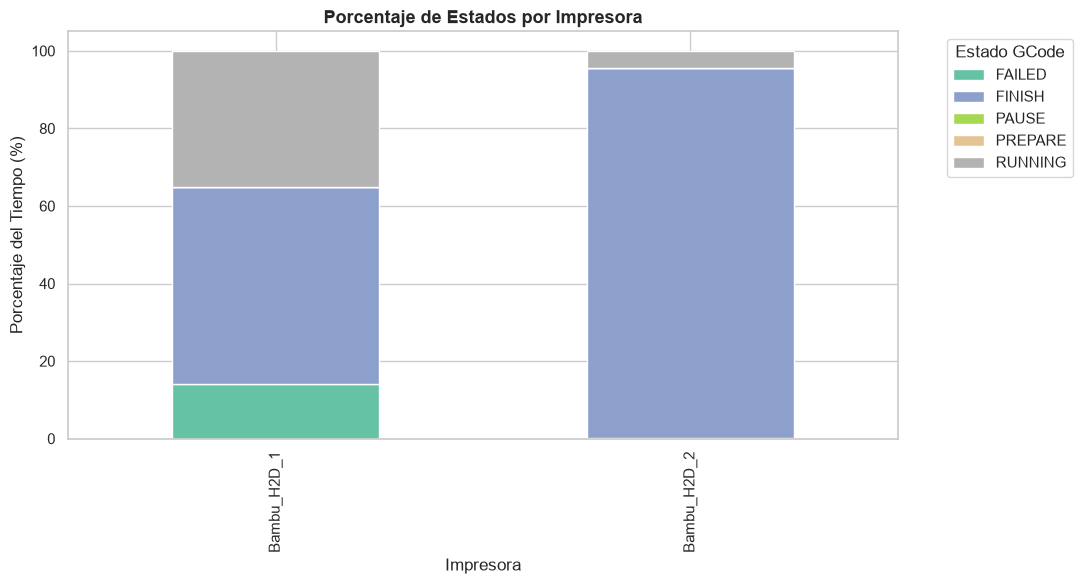

In [34]:
# Crear tabla de frecuencias relativas (porcentaje por impresora)
estados_por_impresora = pd.crosstab(df['printer_name'], df['gcode_state'], normalize='index') * 100

ax = estados_por_impresora.plot(kind='bar', stacked=True, figsize=(11, 6), colormap='Set2')
plt.title('Porcentaje de Estados por Impresora', fontsize=13, fontweight='bold')
plt.xlabel('Impresora')
plt.ylabel('Porcentaje del Tiempo (%)')
plt.legend(title='Estado GCode', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

C:\Users\udaet\AppData\Local\Temp\ipykernel_21552\1177091412.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


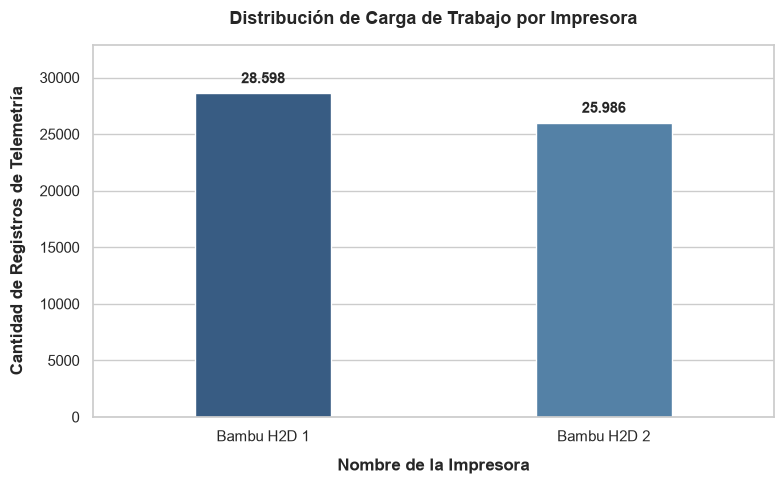

In [35]:
# Crear la figura
plt.figure(figsize=(8, 5))

# Gráfico de barras de carga por impresora
ax = sns.countplot(
    data=df, 
    x='printer_name', 
    palette=['#2b5c8f', '#4682b4'],
    width=0.4
)

# Añadir títulos y etiquetas claras
plt.title('Distribución de Carga de Trabajo por Impresora', fontsize=13, pad=15, fontweight='bold')
plt.xlabel('Nombre de la Impresora', labelpad=10, fontweight='bold')
plt.ylabel('Cantidad de Registros de Telemetría', labelpad=10, fontweight='bold')

# Cambiar los nombres del eje X para que se lean mejor
plt.xticks(ticks=[0, 1], labels=['Bambu H2D 1', 'Bambu H2D 2'])

# Añadir el número exacto de registros encima de cada barra
for p in ax.patches:
    height = int(p.get_height())
    ax.annotate(
        f'{height:,}'.replace(',', '.'),  # Formato con punto de millar
        (p.get_x() + p.get_width() / 2., height),
        ha='center', va='bottom',
        fontsize=11, fontweight='bold',
        xytext=(0, 5), textcoords='offset points'
    )

# Ajustar límites verticales para que la etiqueta no toque el borde superior
plt.ylim(0, max(df['printer_name'].value_counts()) * 1.15)

plt.tight_layout()

# Guardar la imagen en alta calidad para el informe
plt.savefig('grafico_punto4_reparto_impresoras.png', dpi=300)
plt.show()